# Group Project 
## Nike (NKE) vs. Under Armour (UAA)

In [1]:
import sys
!"{sys.executable}" -m pip install pandas numpy matplotlib seaborn openpyxl yfinance


[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [2]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Pandas version:", pd.__version__)

Pandas version: 3.1.1


### Step 1 – Define the tickers (from Yahoo Finance)

In [3]:
tickers = {"Nike": "NKE", "Under_Armour": "UAA"}

### Step 2 – Fetch, merge, and clean the two time series

In [4]:
print("Fetching market data from Yahoo Finance...")
nke_data = yf.Ticker(tickers["Nike"]).history(period="1y")[["Close"]].rename(columns={"Close": "Nike_Close"})
uaa_data = yf.Ticker(tickers["Under_Armour"]).history(period="1y")[["Close"]].rename(columns={"Close": "Under_Armour_Close"})

# Merge by date and drop any incomplete rows (e.g., today's unfinished trading day)
combined_df = pd.merge(nke_data, uaa_data, left_index=True, right_index=True, how="inner").dropna()

# Remove the timezone but keep a real DatetimeIndex (needed for time series work in chapter 8)
combined_df.index = combined_df.index.tz_localize(None).normalize()
combined_df.index.name = "Date"

print("\nRecent Closing Prices (USD):")
print(combined_df.tail())
print("\nRows:", len(combined_df), "| Missing values:", combined_df.isna().sum().sum())

# Export the combined DataFrame to an Excel file
excel_filename = "nike_underarmour_data_export.xlsx"
combined_df.to_excel(excel_filename)
print(f"Data successfully exported to: {excel_filename}")

Fetching market data from Yahoo Finance...

Recent Closing Prices (USD):
            Nike_Close  Under_Armour_Close
Date                                      
2026-11-13   37.990002                4.91
2026-11-16   38.259998                4.85
2026-11-17   35.849998                4.67
2026-11-18   36.310001                4.85
2026-11-19   34.330002                4.48

Rows: 251 | Missing values: 0
Data successfully exported to: nike_underarmour_data_export.xlsx


### Data Visualizations

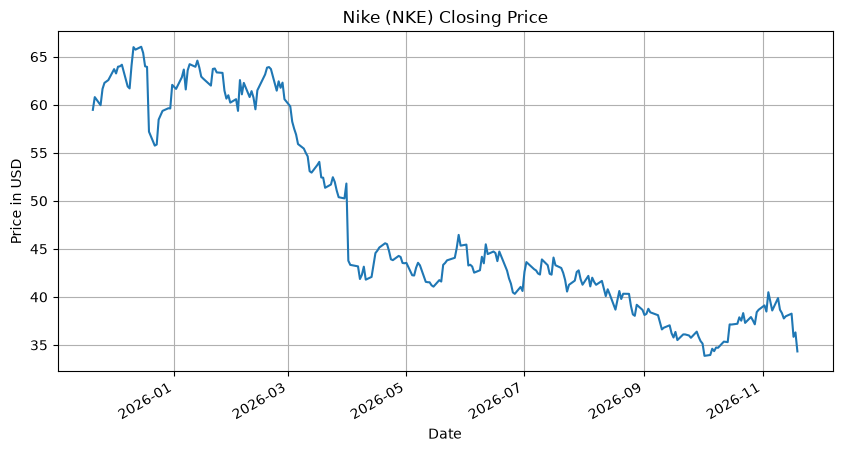

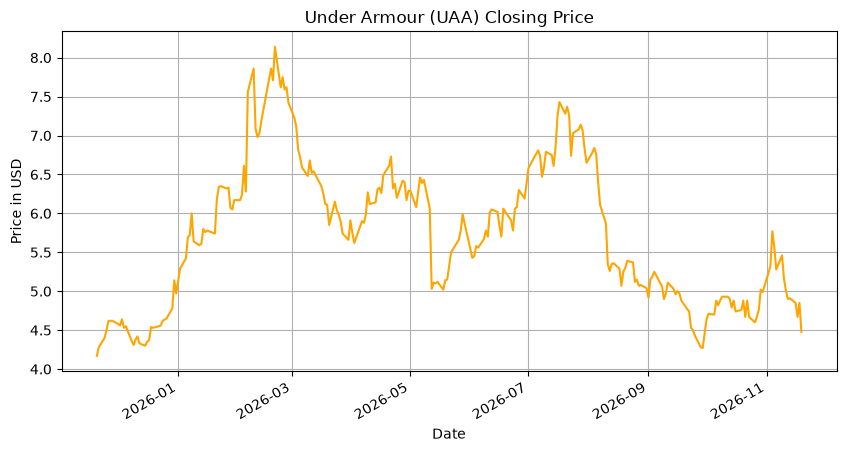

In [5]:
combined_df["Nike_Close"].plot(title="Nike (NKE) Closing Price", ylabel="Price in USD", grid=True, figsize=(10, 5))
plt.show()

combined_df["Under_Armour_Close"].plot(title="Under Armour (UAA) Closing Price", ylabel="Price in USD", grid=True, figsize=(10, 5), color="orange")
plt.show()

- **Nike** peaked at **\$66.04 on Dec 15, 2025** and then fell in steps: a −10.5% day on Dec 19, 2025 and a −15.5% day on Apr 1, 2026. It hit its low of **\$33.87 on Oct 2, 2026** and ended the period near that low at \$34.33.
- **Under Armour** started at its low (**\$4.17**), climbed to a peak of **\$8.14 on Feb 20, 2026**, then returned to around its low of **\$4.48**.

### Comparing the Two Datasets

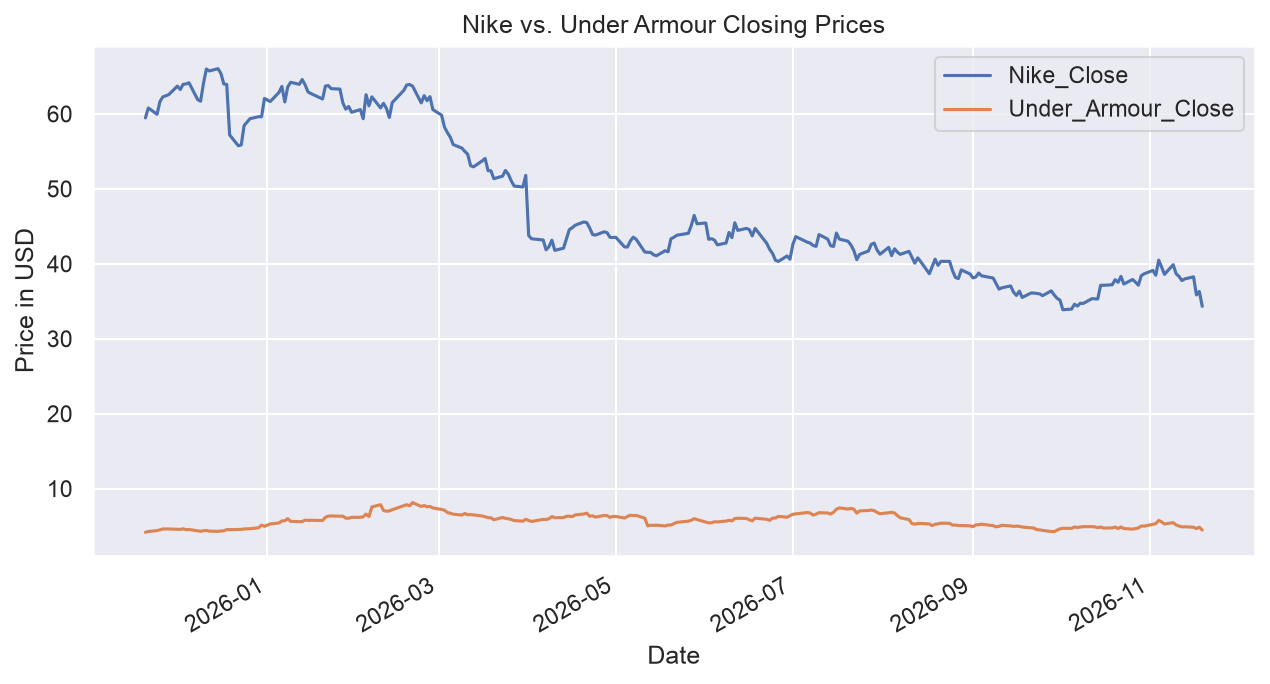

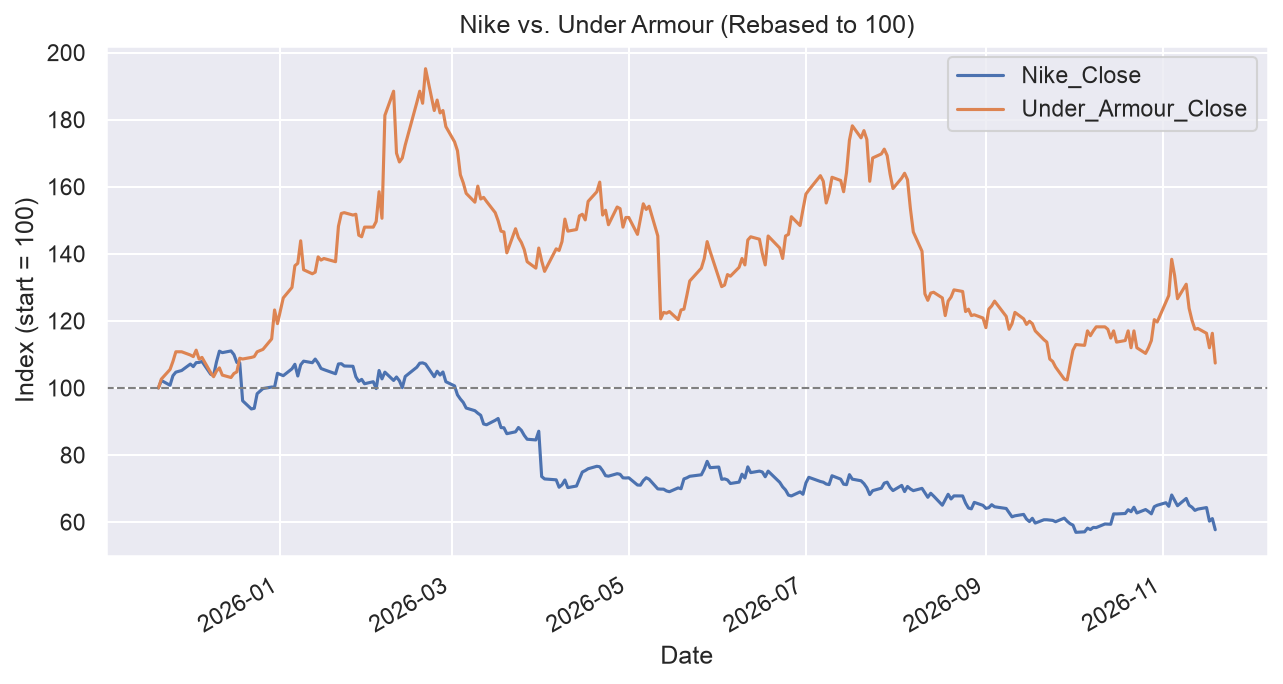

In [35]:
# 1. Side-by-side closing prices
combined_df.plot(title="Nike vs. Under Armour Closing Prices", ylabel="Price in USD", grid=True, figsize=(10, 5))
plt.show()

# 2. Rebased to 100 – Nike trades far higher than UAA, so this shows which performed better
normalized = combined_df / combined_df.iloc[0] * 100
normalized.plot(title="Nike vs. Under Armour (Rebased to 100)", ylabel="Index (start = 100)", grid=True, figsize=(10, 5))
plt.axhline(100, color="gray", linestyle="--", linewidth=1)
plt.show()

**Comparison:** On the raw chart Under Armour looks almost flat, only because it trades at about \$5 against Nike's \$35–\$65. Rebased to 100, the story flips: **Nike lost about 42% over the year, while Under Armour gained about 7%.**

In [36]:
# 3. Summary statistics
print(combined_df.describe().round(2))

# 4. Total return over the period
total_return = (combined_df.iloc[-1] / combined_df.iloc[0] - 1) * 100
print("\nTotal return over the period (%):")
print(total_return.round(2))

       Nike_Close  Under_Armour_Close
count      251.00              251.00
mean        47.45                5.73
std         10.01                0.91
min         33.87                4.17
25%         39.83                4.94
50%         43.34                5.72
75%         59.36                6.35
max         66.04                8.14

Total return over the period (%):
Nike_Close           -42.27
Under_Armour_Close     7.43
dtype: float64


**Summary stats:** Nike averaged \$47.45 and ranged from \$33.87 to \$66.04. Under Armour averaged \$5.73 and ranged from \$4.17 to \$8.14. Nike's median (\$43.34) sits below its mean, because the high prices early in the period pull the average up.

Annualized volatility (%):
Nike_Close            36.99
Under_Armour_Close    55.58
dtype: float64

Correlation of daily returns: 0.407


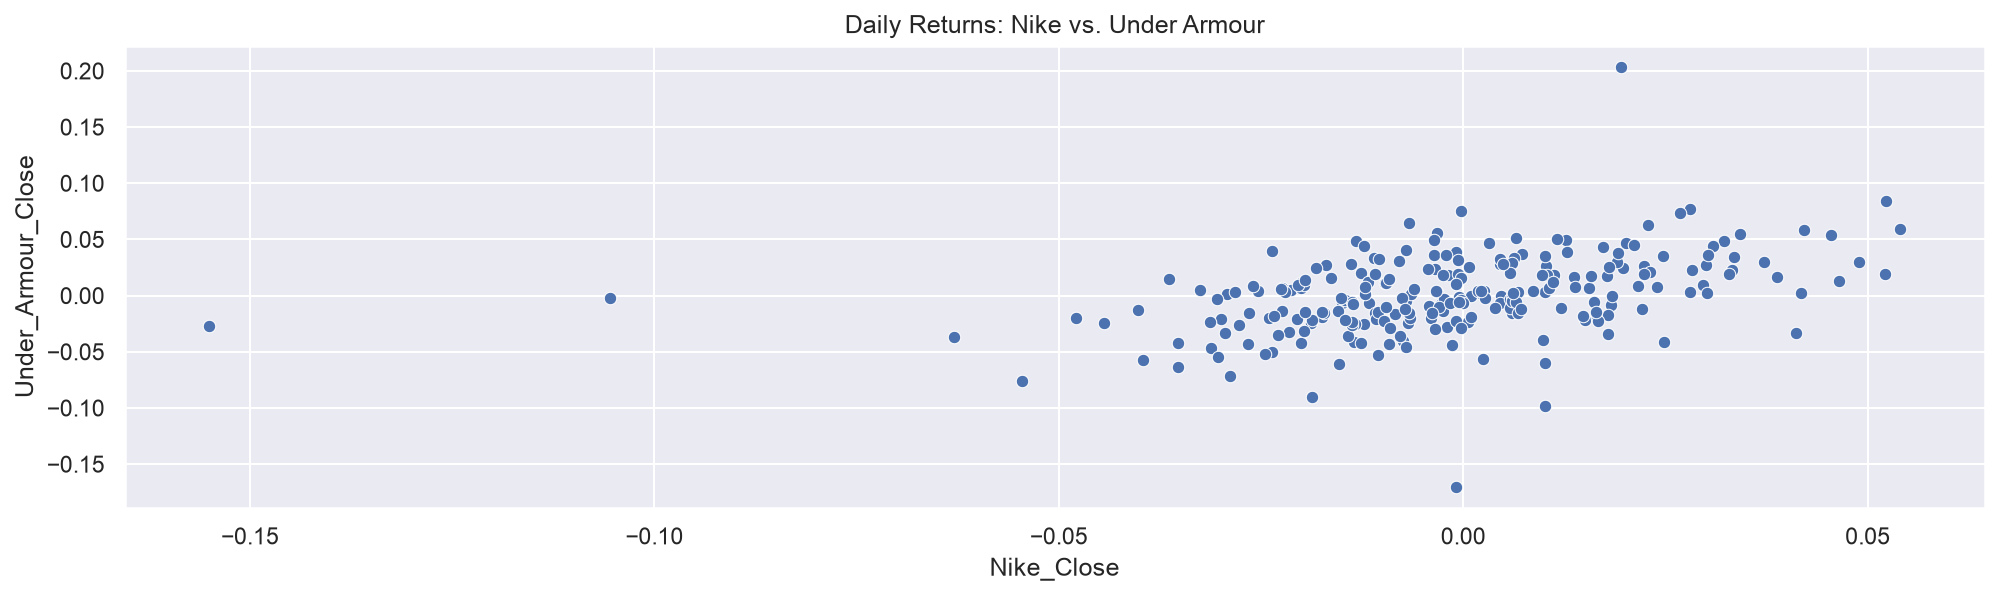

In [37]:
# 5. Daily returns, volatility, and correlation
returns = combined_df.pct_change().dropna()

print("Annualized volatility (%):")
print((returns.std() * np.sqrt(252) * 100).round(2))

print("\nCorrelation of daily returns:", round(returns.corr().iloc[0, 1], 3))

sns.scatterplot(data=returns, x="Nike_Close", y="Under_Armour_Close")
plt.title("Daily Returns: Nike vs. Under Armour")
plt.grid(True)
plt.show()

**Risk and relationship:**
- **Under Armour is the riskier stock:** about 56% annualized volatility versus about 37% for Nike. Its single-day moves were bigger too: +20.4% on Feb 6, 2026 and −17.0% on May 12, 2026.
- **The two stocks move together only moderately:** the correlation of daily returns is about **0.41**. Being in the same industry ties them together somewhat, but each company's own news matters more.

### Step 3 – Chapter 8 Time Series Analysis on Merged Dataset
Every chunk from both Chapter 8 notebooks, run on nike_underarmour_data_export.xlsx.

In [6]:
import os
import numpy as np
import pandas as pd
%matplotlib inline
from matplotlib import pyplot as plt
import seaborn as sns

# Our Step 2 dataset
data = pd.read_excel("nike_underarmour_data_export.xlsx", index_col="Date", parse_dates=True)

# Nike daily returns (%) – our real-world 'zero mean series' (last 50 trading days, like the textbook's size=50)
nke_returns = data["Nike_Close"].pct_change().dropna() * 100
zero_mean_series = nke_returns.tail(50).values
print("Mean of the 50 daily returns:", round(zero_mean_series.mean(), 3), "%")
zero_mean_series

Mean of the 50 daily returns: -0.104 %


array([ 0.49153553,  0.67934784, -2.24021062, -1.21480515,  1.6210225 ,
       -2.33774003,  1.66150431,  0.        , -0.13850205, -0.16642874,
       -0.66685654,  1.79020808, -1.51140216, -1.22767473, -0.70621466,
       -3.64154349,  0.26572234,  1.91402103, -0.72233457,  1.10594023,
       -0.08636325,  1.84384733, -0.05656759, -0.08492101,  5.21246513,
       -0.02692063,  0.21545385,  1.80059661, -0.92397645,  2.10498519,
       -2.66179662,  1.63539041, -0.92323523, -1.09158635,  3.41856417,
        0.65070279,  1.16369481, -1.6359903 ,  5.22349834, -2.29686408,
       -2.45197469,  3.34283729, -3.0341095 , -0.90509049, -1.46138147,
        0.60911909,  0.71070448, -6.29900667,  1.28313227, -5.45304177])

**Zero mean model:** Nike's last 50 daily returns average **−0.10%**, very close to zero, but individual days swing a lot (about ±2.2% typically, from −6.3% to +5.2%).

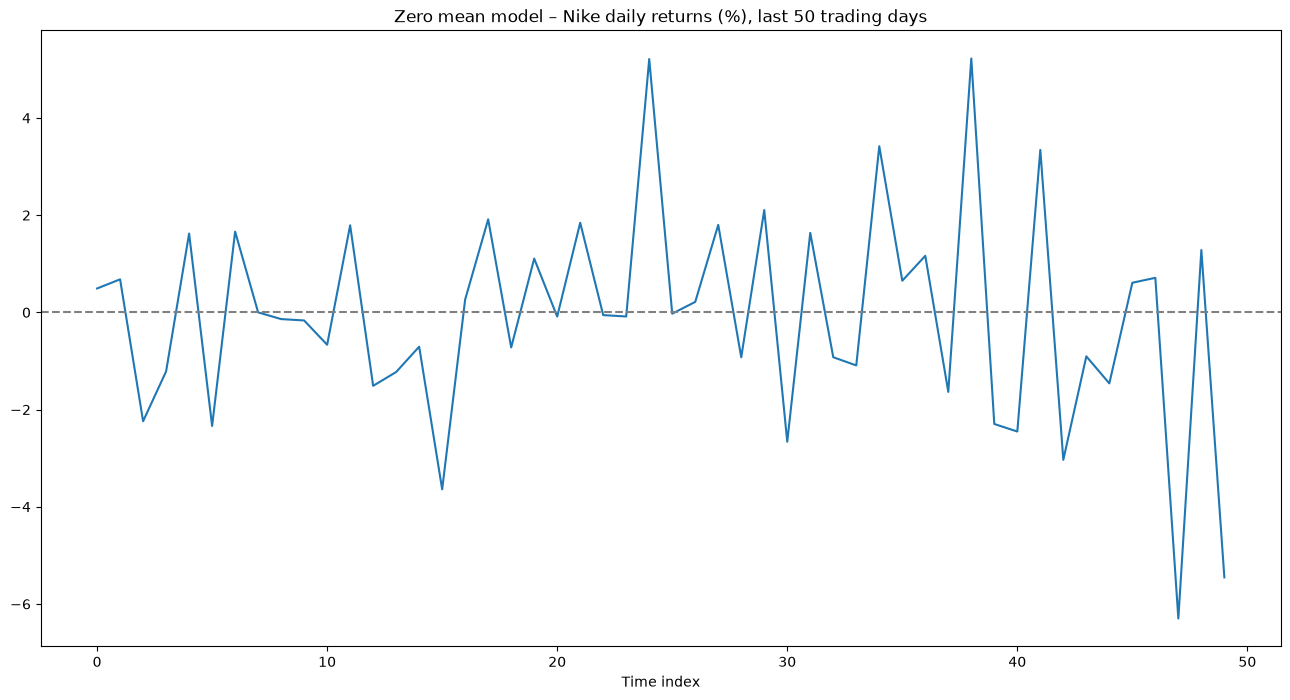

In [7]:
plt.figure(figsize=(16, 8))
g = sns.lineplot(data=zero_mean_series)
g.axhline(0, color="gray", linestyle="--")
g.set_title('Zero mean model – Nike daily returns (%), last 50 trading days')
g.set_xlabel('Time index')
plt.show()

In [8]:
random_walk = np.cumsum(zero_mean_series)

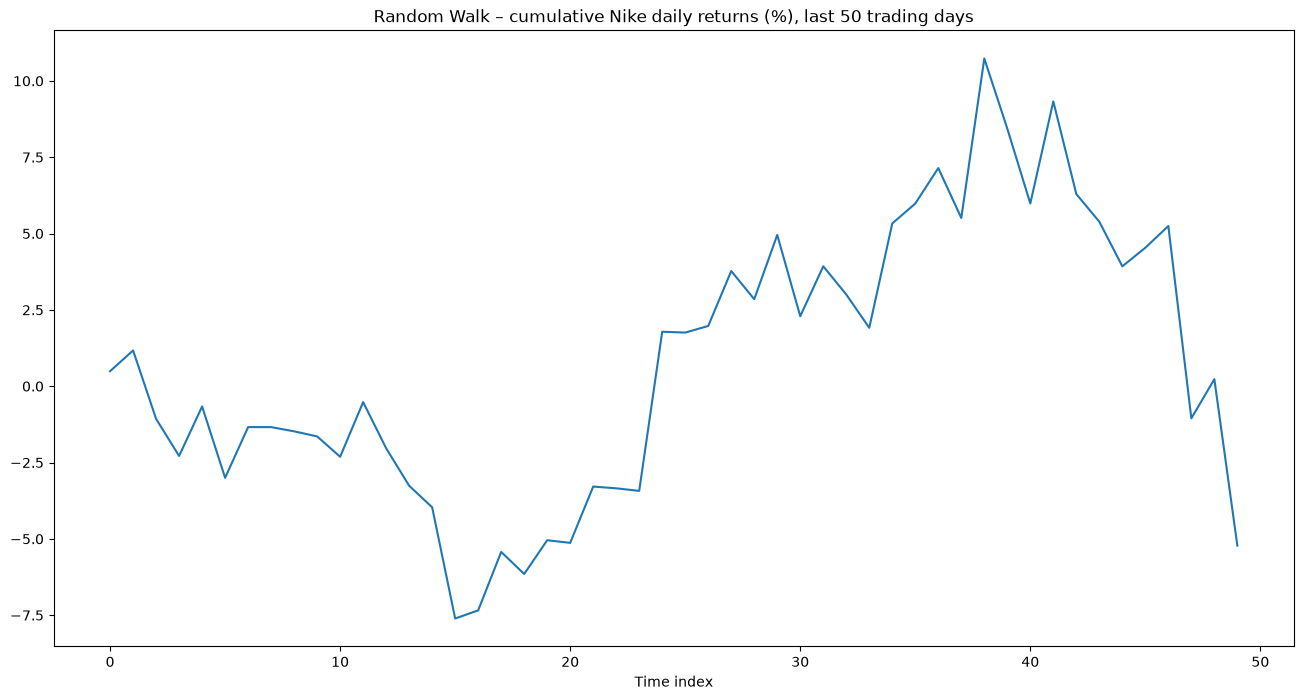

In [9]:
plt.figure(figsize=(16, 8))
g = sns.lineplot(data=random_walk)
g.set_title('Random Walk – cumulative Nike daily returns (%), last 50 trading days')
g.set_xlabel('Time index')
plt.show()

**Random walk:** Adding up those near-zero daily returns produces a path that wanders, up as much as +10.7% and down to −7.6% over the 50 days, ending at −5.2%.

##### Time Series Analysis

In [11]:
# load time series dataset (our Step 2 export)
df_stocks = pd.read_excel("nike_underarmour_data_export.xlsx")
df_stocks.columns

Index(['Date', 'Nike_Close', 'Under_Armour_Close'], dtype='str')

In [12]:
df_stocks.tail(10)

,Date,Nike_Close,Under_Armour_Close
241,2026-11-06,38.590000,5.28
242,2026-11-09,39.880001,5.46
243,2026-11-10,38.669998,5.16
244,2026-11-11,38.320000,5.01
245,2026-11-12,37.759998,4.90
246,2026-11-13,37.990002,4.91
247,2026-11-16,38.259998,4.85
248,2026-11-17,35.849998,4.67
249,2026-11-18,36.310001,4.85
250,2026-11-19,34.330002,4.48


We have one year of daily closing prices for both Nike and Under Armour.

In [13]:
df_stocks.shape

(251, 3)

In [14]:
df_stocks.dtypes

Date                  datetime64[us]
Nike_Close                   float64
Under_Armour_Close           float64
dtype: object

In [15]:
#convert to datetime format (already datetime from Excel)
df_stocks['Date'] = pd.to_datetime(df_stocks['Date'])

In [16]:
df_stocks.dtypes

Date                  datetime64[us]
Nike_Close                   float64
Under_Armour_Close           float64
dtype: object

Now that the Date column is in the correct datatype, let's set it as the DataFrame's index, because in time series analysis the index is always the datetime column.

In [17]:
df_stocks = df_stocks.set_index('Date')
df_stocks.tail(3)

,Nike_Close,Under_Armour_Close
Date,,
2026-11-17,35.849998,4.67
2026-11-18,36.310001,4.85
2026-11-19,34.330002,4.48


In [18]:
df_stocks.index

DatetimeIndex(['2025-11-20', '2025-11-21', '2025-11-24', '2025-11-25',
               '2025-11-26', '2025-11-28', '2025-12-01', '2025-12-02',
               '2025-12-03', '2025-12-04',
               ...
               '2026-11-06', '2026-11-09', '2026-11-10', '2026-11-11',
               '2026-11-12', '2026-11-13', '2026-11-16', '2026-11-17',
               '2026-11-18', '2026-11-19'],
              dtype='datetime64[us]', name='Date', length=251, freq=None)

In [19]:
# Add daily returns (%) for each stock
df_stocks['Nike_Return'] = df_stocks['Nike_Close'].pct_change() * 100
df_stocks['UA_Return'] = df_stocks['Under_Armour_Close'].pct_change() * 100

# Add columns with year, month, and weekday name
df_stocks['Year'] = df_stocks.index.year
df_stocks['Month'] = df_stocks.index.month
df_stocks['Weekday Name'] = df_stocks.index.day_name()   # textbook's .weekday_name was removed from pandas

In [20]:
# Display a random sampling of 5 rows
df_stocks.sample(5, random_state=0)

,Nike_Close,Under_Armour_Close,Nike_Return,UA_Return,Year,Month,Weekday Name
Date,,,,,,,
2026-07-06,42.885075,6.81,-1.701064,2.714929,2026,7,Monday
2026-05-19,41.602470,5.14,-0.352363,2.390436,2026,5,Tuesday
2026-04-07,41.867264,5.88,-3.043387,-0.338983,2026,4,Tuesday
2026-07-13,43.300663,6.75,-1.374809,-0.589101,2026,7,Monday
2026-06-29,41.044598,6.19,1.791407,-1.746034,2026,6,Monday


In [21]:
df_stocks.loc['2026-03-02']

Nike_Close            59.834194
Under_Armour_Close         7.23
Nike_Return           -1.230378
UA_Return             -2.560648
Year                       2026
Month                         3
Weekday Name             Monday
Name: 2026-03-02 00:00:00, dtype: object

In [22]:
df_stocks.loc['2026-01-01':'2026-06-30']

,Nike_Close,Under_Armour_Close,Nike_Return,UA_Return,Year,Month,Weekday Name
Date,,,,,,,
2026-01-02,61.651237,5.29,-0.674930,6.438636,2026,1,Friday
2026-01-05,62.869061,5.42,1.975342,2.457469,2026,1,Monday
2026-01-06,63.667961,5.69,1.270737,4.981549,2026,1,Tuesday
2026-01-07,61.592785,5.72,-3.259373,0.527236,2026,1,Wednesday
2026-01-08,63.580284,6.00,3.226838,4.895109,2026,1,Thursday
...,...,...,...,...,...,...,...
2026-06-24,41.381027,6.06,-1.321381,4.844286,2026,6,Wednesday
2026-06-25,40.470688,6.08,-2.199895,0.330033,2026,6,Thursday
2026-06-26,40.322262,6.30,-0.366750,3.618425,2026,6,Friday


**First half of 2026:** Nike went from \$61.65 on Jan 2 to \$40.62 on Jun 30, losing roughly a third of its value in six months. Most of the losses came in March and April.

**Visualization for time series analysis**

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(rc={'figure.figsize':(16, 4)})
plt.rcParams['figure.dpi'] = 150

Line plot of Nike's full year of closing prices, using pandas's `plot()` method.

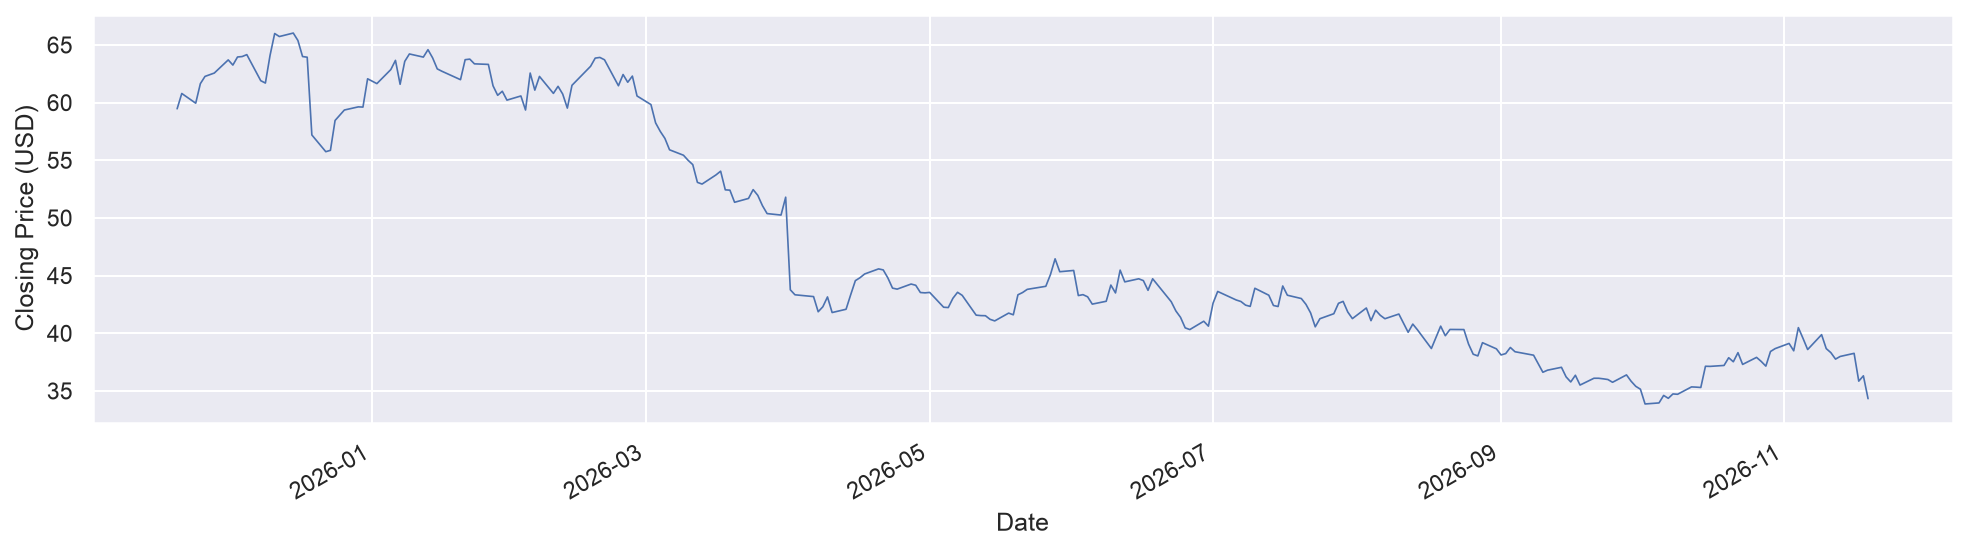

In [24]:
ax = df_stocks['Nike_Close'].plot(linewidth=0.8)
ax.set_ylabel('Closing Price (USD)');

**Full year:** The line plot shows a clear **downtrend** for Nike: from about \$60 down to about \$34, with sharp single-day drops rather than a smooth decline.

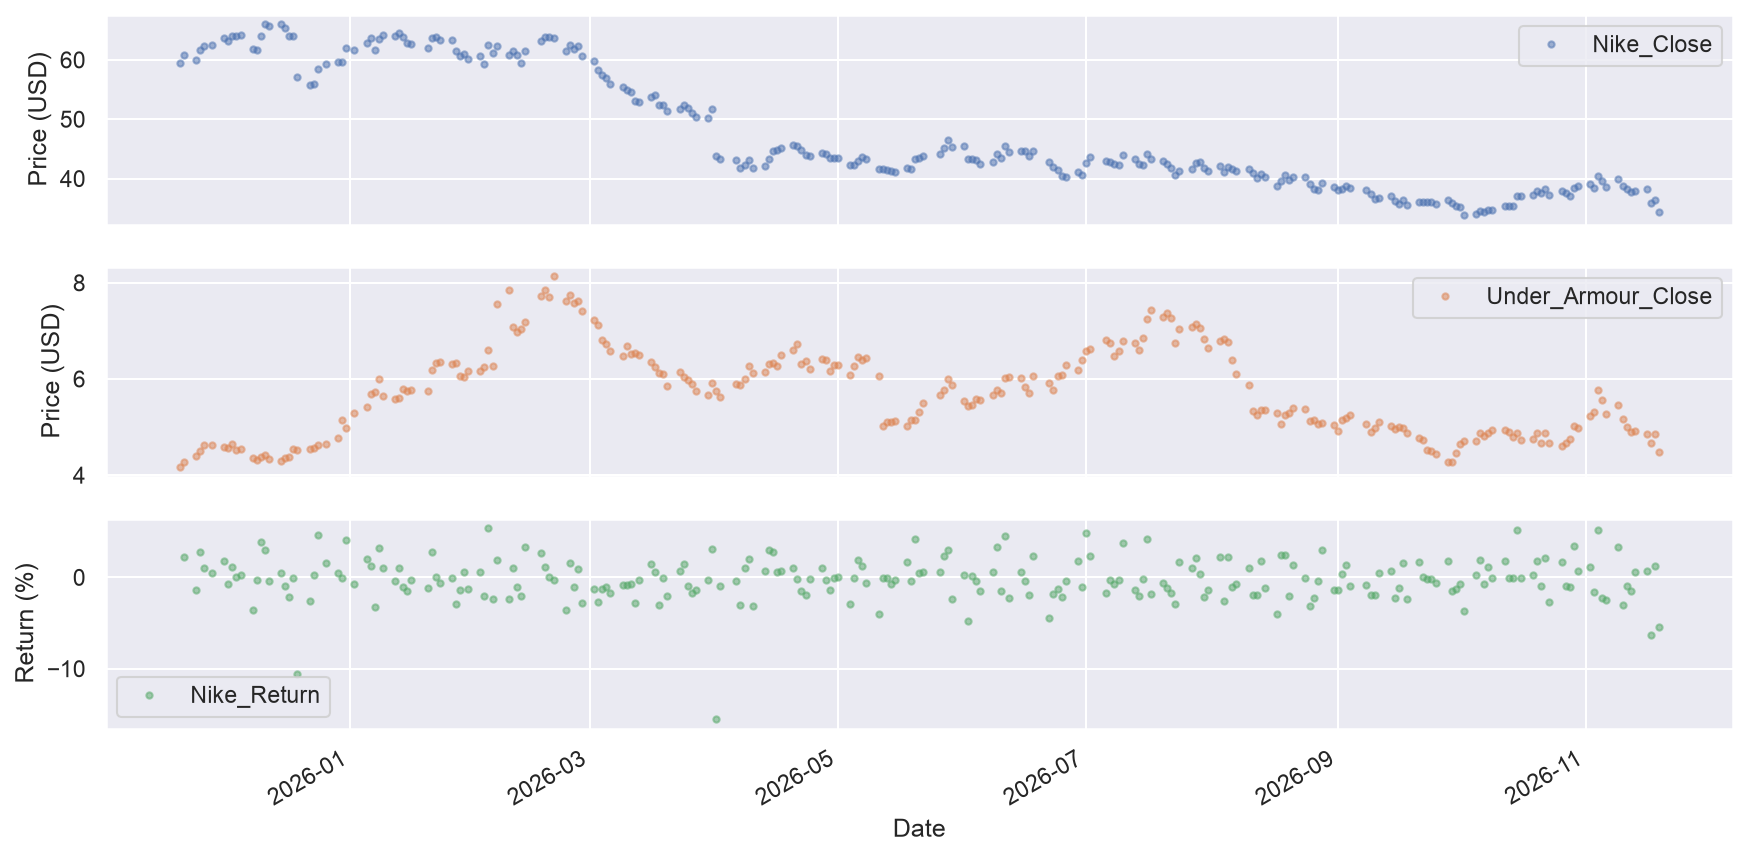

In [25]:
cols_to_plot = ['Nike_Close', 'Under_Armour_Close', 'Nike_Return']
axes = df_stocks[cols_to_plot].plot(marker='.', alpha=0.5, linestyle='None', figsize=(14, 7), subplots=True)
for ax, label in zip(axes, ['Price (USD)', 'Price (USD)', 'Return (%)']):
    ax.set_ylabel(label)

**Three views at once:** The two price panels show different paths: Nike trends down, Under Armour rises and then falls back. The returns panel stays centered on zero the whole year. The few dots far from zero are the big news-driven days, and those are what moved the price.

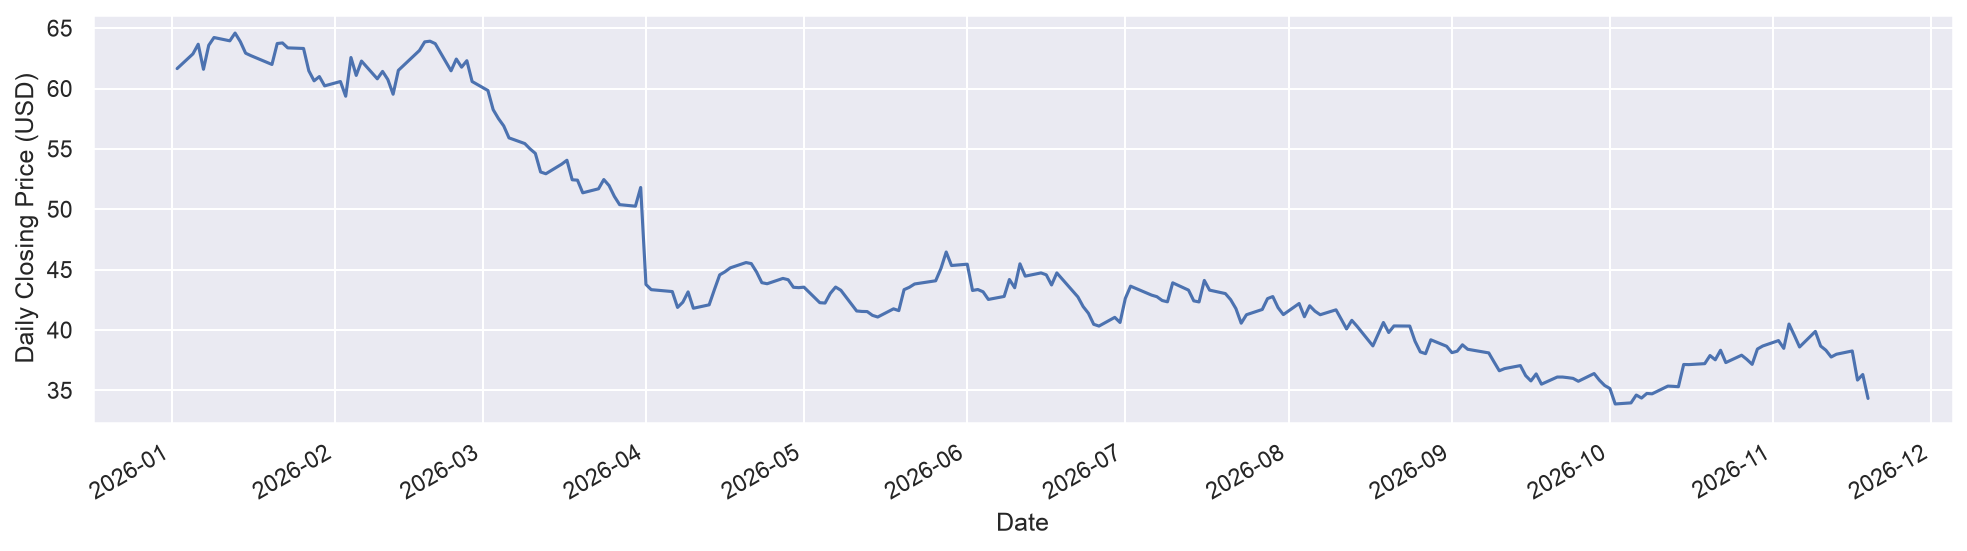

In [26]:
ax = df_stocks.loc['2026', 'Nike_Close'].plot()
ax.set_ylabel('Daily Closing Price (USD)');

Nike's high for 2026 was \$64.59 on Jan 13. It is down about 44% for the year to date.

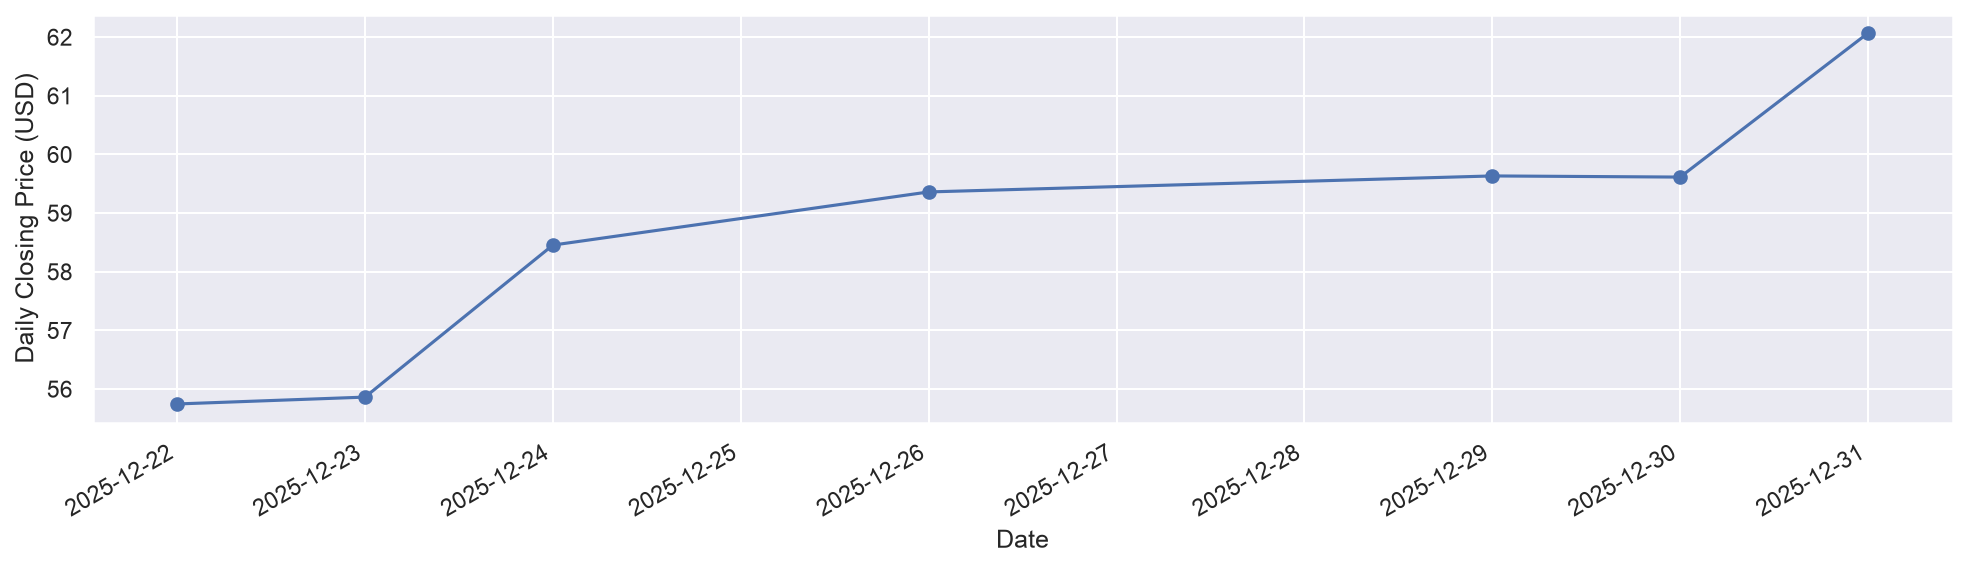

In [27]:
ax = df_stocks.loc['2025-12-22':'2025-12-31', 'Nike_Close'].plot(marker='o', linestyle='-')
ax.set_ylabel('Daily Closing Price (USD)');

**Holiday week:** After the Dec 19 drop, Nike rebounded steadily through the last week of December, from \$55.75 on Dec 22 to \$62.07 on Dec 31 (about +11%).

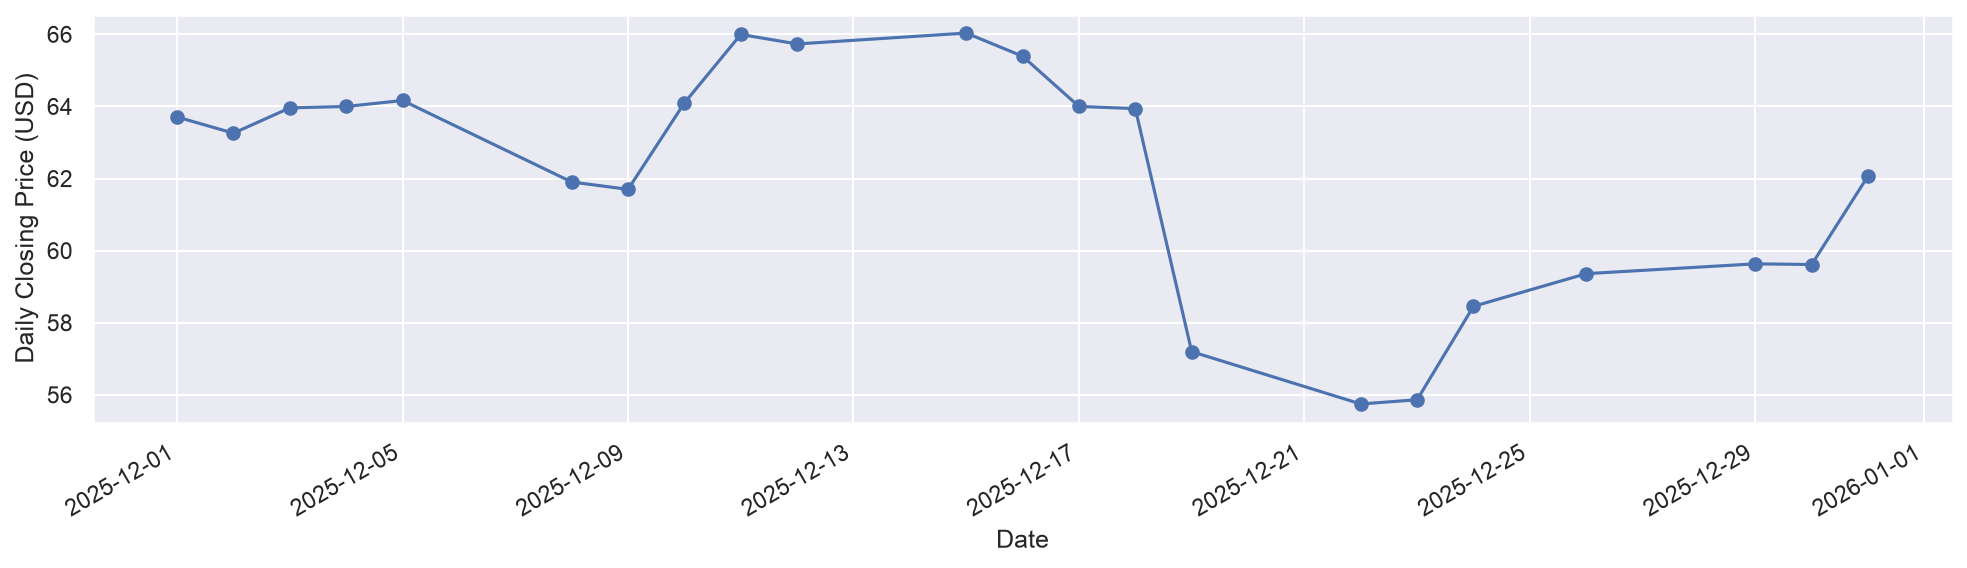

In [28]:
ax = df_stocks.loc['2025-12', 'Nike_Close'].plot(marker='o', linestyle='-')
ax.set_ylabel('Daily Closing Price (USD)');

**December 2025:** A volatile month. Nike hit its yearly high (\$66.04) mid-month, fell to \$55.75 after the Dec 19 drop, then recovered to \$62.07 by month-end.

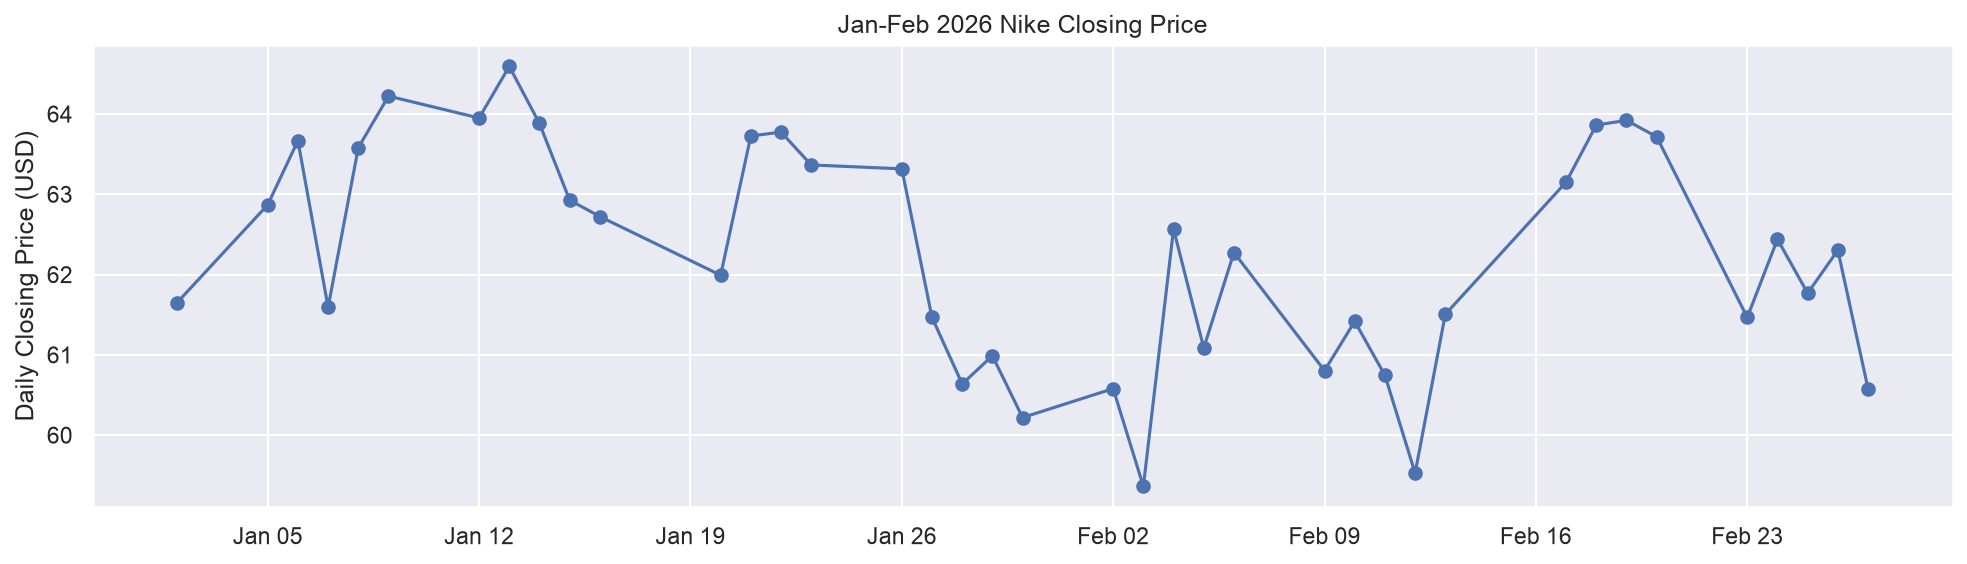

In [29]:
# import dates module from matplotlib
import matplotlib.dates as mdates

# plot graph
fig, ax = plt.subplots()

ax.plot(df_stocks.loc['2026-01':'2026-02', 'Nike_Close'], marker='o', linestyle='-')
ax.set_ylabel('Daily Closing Price (USD)')
ax.set_title('Jan-Feb 2026 Nike Closing Price')

# to set x-axis major ticks to weekly interval, on Mondays
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MONDAY))
# to set format for x-tick labels as 3-letter month name and day number
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'));

**Jan–Feb 2026:** Nike traded sideways in a fairly tight range (\$59.36–\$64.59), starting at \$61.65 and ending February at \$60.58.

**Seasonality**

With one year of data, each month box mostly reflects that month's price level and how much it moved (November includes days from both 2025 and 2026).

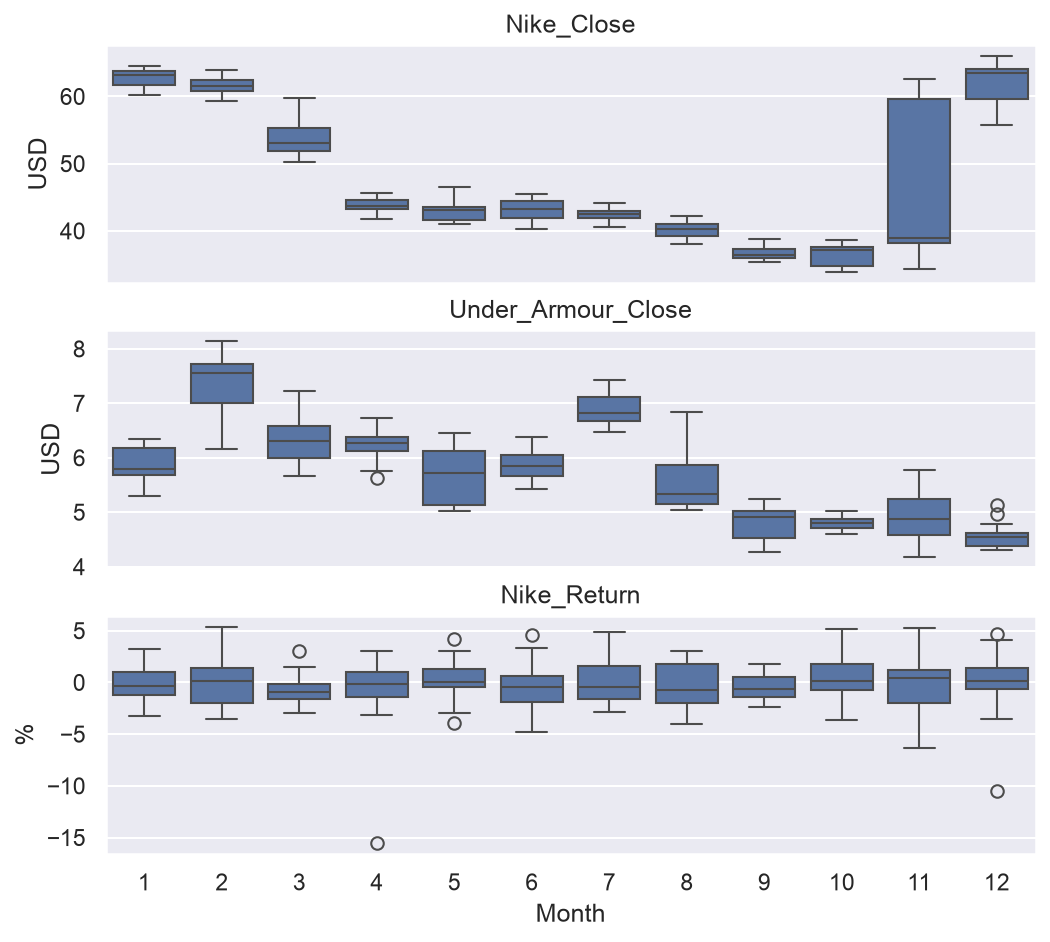

In [30]:
fig, axes = plt.subplots(3, 1, figsize=(8, 7), sharex=True)
for name, ylabel, ax in zip(['Nike_Close', 'Under_Armour_Close', 'Nike_Return'], ['USD', 'USD', '%'], axes):
    sns.boxplot(data=df_stocks, x='Month', y=name, ax=ax)
    ax.set_ylabel(ylabel)
    ax.set_title(name)
    if ax != axes[-1]:
        ax.set_xlabel('')

**Monthly boxplots:** With only one year of data, these boxes show the **trend**, not true seasonality. Nike's boxes step down month by month, from an average of about \$62 in Dec/Jan to about \$36 in Sep/Oct. Under Armour's peak in February stands out. The returns panel stays centered near zero every month; April has the widest spread because of the −15.5% day.

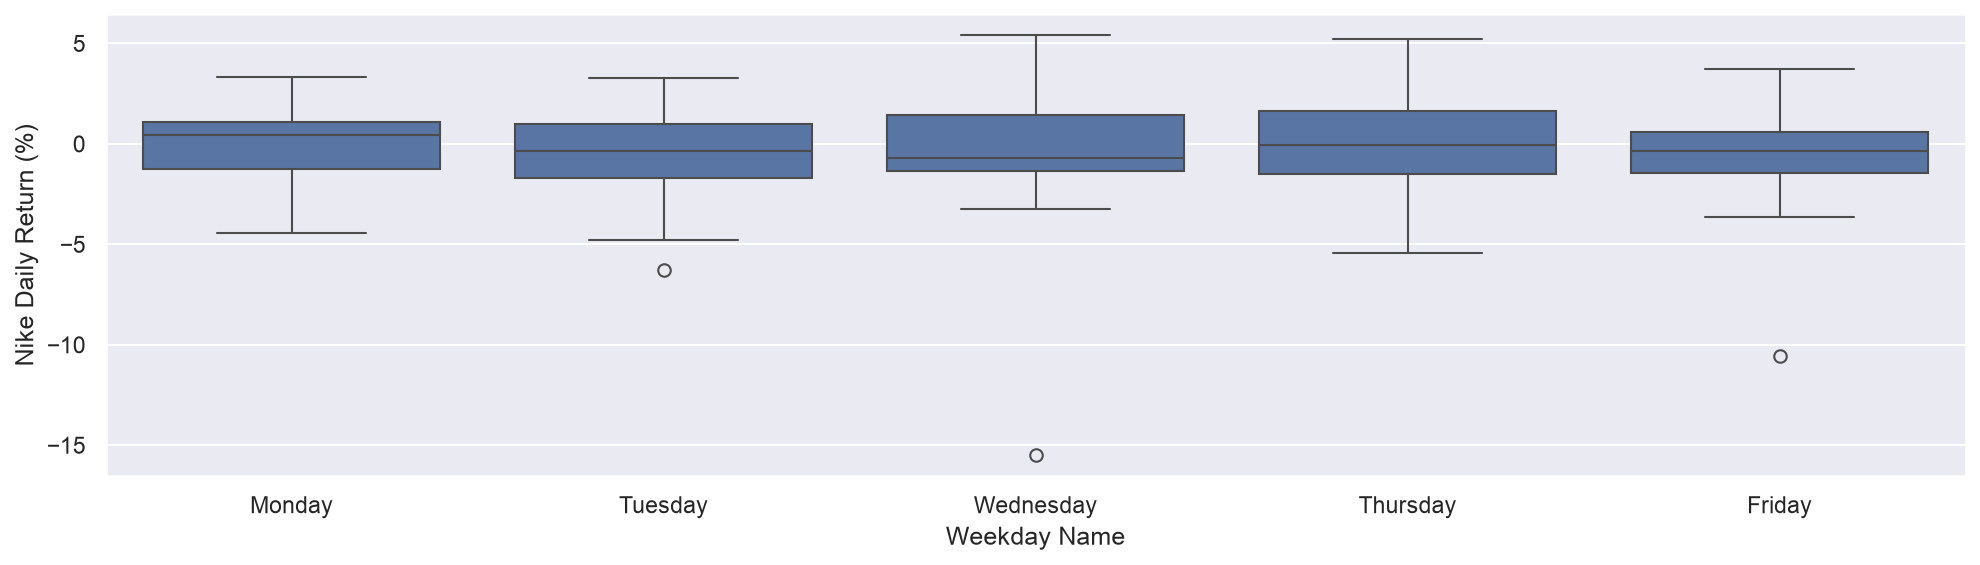

In [31]:
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']
ax = sns.boxplot(data=df_stocks, x='Weekday Name', y='Nike_Return', order=day_order)
ax.set_ylabel('Nike Daily Return (%)');

**Day of the week:** All five weekday boxes overlap heavily and their medians sit near zero. Friday's average return is the lowest (−0.55%), but with one year of data that difference is too small to call a real weekday effect.

In [32]:
columns = ['Nike_Close', 'Under_Armour_Close', 'Nike_Return', 'UA_Return']

stocks_weekly_mean = df_stocks[columns].resample('W').mean()
stocks_weekly_mean.head(10)

,Nike_Close,Under_Armour_Close,Nike_Return,UA_Return
Date,,,,
2025-11-23,60.132324,4.2250,2.230182,2.637893
2025-11-30,61.611067,4.5350,0.731872,1.935781
2025-12-07,63.817994,4.5720,0.509400,-0.295456
2025-12-14,63.886193,4.3600,0.519336,-0.964289
2025-12-21,63.313329,4.4180,-2.656016,0.919924
2025-12-28,57.357183,4.5950,0.965203,0.656605
2026-01-04,60.742740,5.0450,0.967564,3.364579
2026-01-11,63.186674,5.6940,0.844972,1.372272
2026-01-18,63.615350,5.7080,-0.468009,0.503128


**Weekly resampling:** Taking the weekly mean (`resample('W')`) turns about 251 daily rows into about 53 weekly ones,  reducing day-to-day noise while keeping the overall shape.

In [33]:
start, end = '2026-01', '2026-06'

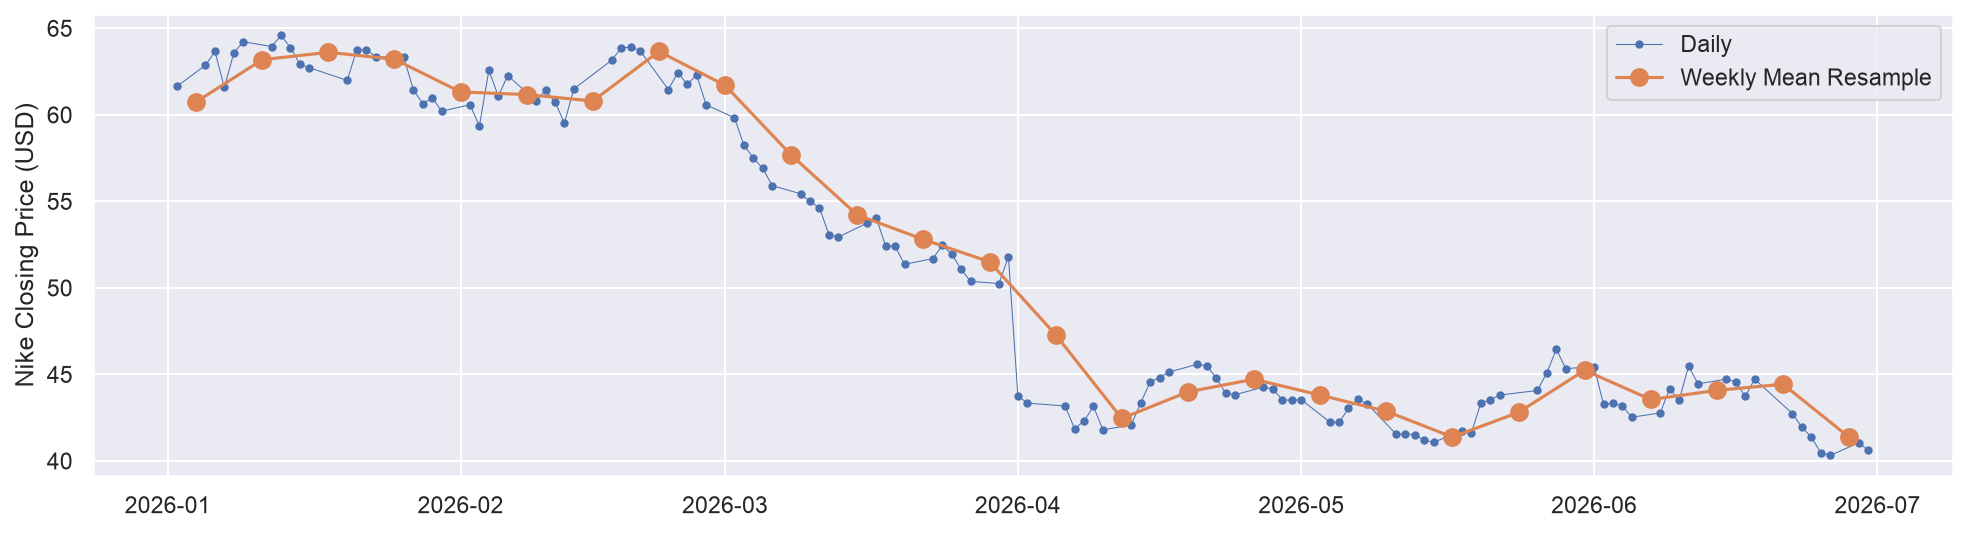

In [34]:
fig, ax = plt.subplots()

ax.plot(df_stocks.loc[start:end, 'Nike_Close'],
        marker='.', linestyle='-', linewidth=0.5, label='Daily')
ax.plot(stocks_weekly_mean.loc[start:end, 'Nike_Close'],
        marker='o', markersize=8, linestyle='-', label='Weekly Mean Resample')
ax.set_ylabel('Nike Closing Price (USD)')
ax.legend();

**Daily vs. weekly:** The weekly mean line follows the daily prices but removes the jagged day-to-day moves. It makes the Jan–Jun 2026 decline easier to see: steady through February, a sharp drop in March–April, then a lower plateau around \$41–\$45.